# books.toscrape.com — Veri Analizi

Bu notebook `scraper.py` ile çekilip `clean.py` ile temizlenen **`kitaplar.csv`** dosyasını analiz eder.

Cevaplanan sorular:
1. Kategori başına ortalama fiyat nedir? (en pahalı 10 kategori)
2. Kitapların puan dağılımı nasıldır?
3. Puanı yüksek kitaplar daha mı pahalı?

Kullanılan kütüphaneler: **pandas**, **matplotlib**, **seaborn**.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
CHART_DIR = Path("charts")
CHART_DIR.mkdir(exist_ok=True)

df = pd.read_csv("kitaplar.csv")
print(df.shape)
df.head()

(1000, 8)


,baslik,fiyat,puan,stok_durumu,stok_adedi,kategori,upc,url
0,A Light in the Attic,51.77,3,In stock,22,Poetry,a897fe39b1053632,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,20,Historical Fiction,90fa61229261140a,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,20,Fiction,6957f44c3847a760,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,20,Mystery,e00eb4fd7b871a48,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,20,History,4165285e1663650f,https://books.toscrape.com/catalogue/sapiens-a...


## 1. Veri kalitesi kontrolü

Analizden önce verinin eksiksiz ve sayısal alanların doğru tipte olduğunu kontrol ediyoruz.

In [2]:
site = json.loads(Path("data/site_info.json").read_text(encoding="utf-8"))

print("Satır sayısı      :", len(df), "| sitede yazan:", site["total_results"])
print("Kategori sayısı   :", df["kategori"].nunique(), "| sitede:", site["n_categories"])
print("UPC tekil mi      :", df["upc"].is_unique)
print("fiyat tipi        :", df["fiyat"].dtype, "| aralık:", df["fiyat"].min(), "-", df["fiyat"].max())
print("puan tipi         :", df["puan"].dtype, "| değerler:", sorted(df["puan"].unique()))
print("\nBoş değerler:")
print(df.isna().sum())

Satır sayısı      : 1000 | sitede yazan: 1000
Kategori sayısı   : 50 | sitede: 50
UPC tekil mi      : True
fiyat tipi        : float64 | aralık: 10.0 - 59.99
puan tipi         : int64 | değerler: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Boş değerler:
baslik         0
fiyat          0
puan           0
stok_durumu    0
stok_adedi     0
kategori       0
upc            0
url            0
dtype: int64


In [3]:
df[["fiyat", "puan", "stok_adedi"]].describe().round(2)

,fiyat,puan,stok_adedi
count,1000.00,1000.00,1000.00
mean,35.07,2.92,8.59
std,14.45,1.43,5.65
min,10.00,1.00,1.00
25%,22.11,2.00,3.00
50%,35.98,3.00,7.00
75%,47.46,4.00,14.00
max,59.99,5.00,22.00


## 2. Kategori başına ortalama fiyat (en pahalı 10 kategori)

In [4]:
by_cat = (df.groupby("kategori")["fiyat"]
            .agg(ortalama_fiyat="mean", kitap_sayisi="count")
            .sort_values("ortalama_fiyat", ascending=False))
top10 = by_cat.head(10)
top10.round(2)

,ortalama_fiyat,kitap_sayisi
kategori,,
Suspense,58.33,1
Novels,54.81,1
Politics,53.61,3
Health,51.45,4
New Adult,46.38,6
Christian,42.50,3
Sports and Games,41.17,5
Self Help,40.62,5
Travel,39.79,11


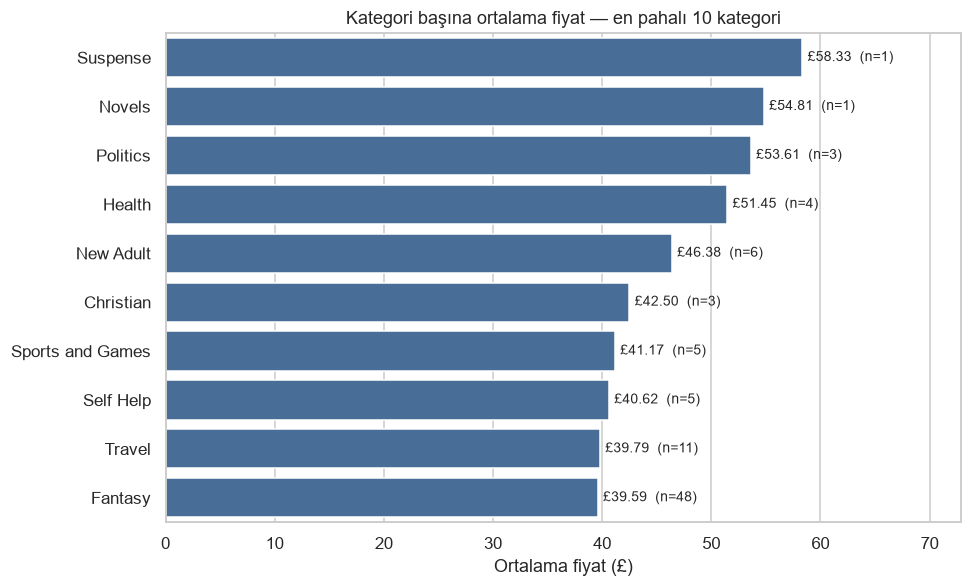

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=top10.reset_index(), y="kategori", x="ortalama_fiyat", color="#3b6ea5", ax=ax)
for i, (mean, n) in enumerate(top10[["ortalama_fiyat", "kitap_sayisi"]].values):
    ax.text(mean + 0.5, i, f"£{mean:.2f}  (n={int(n)})", va="center", fontsize=9)
ax.set_xlim(0, top10["ortalama_fiyat"].max() * 1.25)
ax.set_xlabel("Ortalama fiyat (£)")
ax.set_ylabel("")
ax.set_title("Kategori başına ortalama fiyat — en pahalı 10 kategori")
fig.tight_layout()
fig.savefig(CHART_DIR / "kategori_ortalama_fiyat_top10.png", dpi=150)
plt.show()

**Yorum:** Listenin başındaki kategorilerin çoğunda çok az kitap var (`n` değeri). Örneğin en üstteki kategorinin ortalaması tek bir kitabın fiyatı olabilir. Bu yüzden bu sıralama "o türün kitapları pahalıdır" şeklinde genellenmemeli. Daha güvenilir bir karşılaştırma için en az 10 kitabı olan kategorilere aşağıda ayrıca bakıyoruz.

Not: Sitede **"Default"** ve **"Add a comment"** adında, gerçek bir tür olmayan yer tutucu kategoriler var. Veri sitedeki haliyle bırakıldı, silinmedi.

In [6]:
by_cat[by_cat["kitap_sayisi"] >= 10].head(10).round(2)

,ortalama_fiyat,kitap_sayisi
kategori,,
Travel,39.79,11
Fantasy,39.59,48
History,37.29,18
Womens Fiction,36.79,17
Classics,36.55,19
Fiction,36.07,65
Poetry,35.97,19
Horror,35.95,17
Add a comment,35.80,67


## 3. Kitapların puan dağılımı

In [7]:
dist = df["puan"].value_counts().sort_index()
pd.DataFrame({"kitap_sayisi": dist, "yuzde": (dist / len(df) * 100).round(1)})

,kitap_sayisi,yuzde
puan,,
1,226,22.6
2,196,19.6
3,203,20.3
4,179,17.9
5,196,19.6


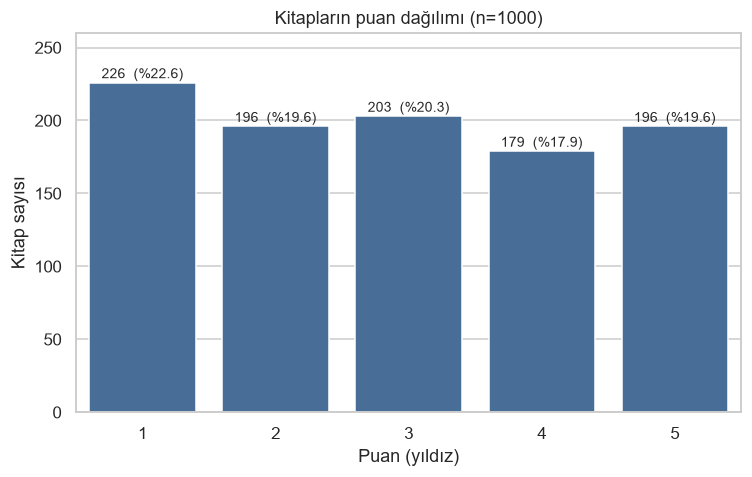

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(data=df, x="puan", color="#3b6ea5", ax=ax)
for p in ax.patches:
    h = p.get_height()
    ax.text(p.get_x() + p.get_width() / 2, h + 3, f"{int(h)}  (%{h / len(df) * 100:.1f})", ha="center", fontsize=9)
ax.set_ylim(0, dist.max() * 1.15)
ax.set_xlabel("Puan (yıldız)")
ax.set_ylabel("Kitap sayısı")
ax.set_title(f"Kitapların puan dağılımı (n={len(df)})")
fig.tight_layout()
fig.savefig(CHART_DIR / "puan_dagilimi.png", dpi=150)
plt.show()

**Yorum:** Puanlar 1-5 arasında oldukça dengeli dağılmış. En kalabalık grup 1 yıldız, en az kitap 4 yıldızda. Belirgin bir yüksek veya düşük puan yığılması yok.

## 4. Puanı yüksek kitaplar daha mı pahalı?

In [9]:
by_rating = df.groupby("puan")["fiyat"].agg(kitap_sayisi="count", ortalama="mean", medyan="median").round(2)
pearson = df["fiyat"].corr(df["puan"])
spearman = df["fiyat"].rank().corr(df["puan"].rank())
print(f"Pearson r  = {pearson:.3f}")
print(f"Spearman r = {spearman:.3f}")
print(f"Puan grupları arasındaki en büyük ortalama fark = £{by_rating['ortalama'].max() - by_rating['ortalama'].min():.2f}")
by_rating

Pearson r  = 0.028
Spearman r = 0.029
Puan grupları arasındaki en büyük ortalama fark = £1.53


,kitap_sayisi,ortalama,medyan
puan,,,
1,226,34.56,34.77
2,196,34.81,36.22
3,203,34.69,33.78
4,179,36.09,37.80
5,196,35.37,36.90


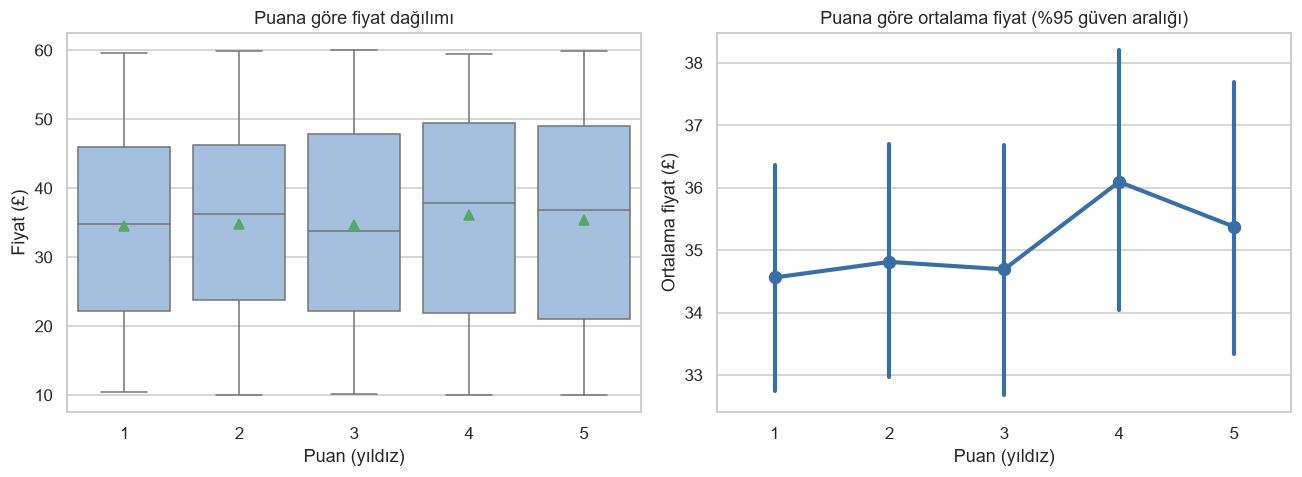

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x="puan", y="fiyat", color="#9cc0e7", showmeans=True, ax=axes[0])
axes[0].set_title("Puana göre fiyat dağılımı")
axes[0].set_xlabel("Puan (yıldız)")
axes[0].set_ylabel("Fiyat (£)")

sns.pointplot(data=df, x="puan", y="fiyat", errorbar=("ci", 95), color="#3b6ea5", ax=axes[1])
axes[1].set_title("Puana göre ortalama fiyat (%95 güven aralığı)")
axes[1].set_xlabel("Puan (yıldız)")
axes[1].set_ylabel("Ortalama fiyat (£)")
fig.tight_layout()
fig.savefig(CHART_DIR / "puan_vs_fiyat.png", dpi=150)
plt.show()

### Cevap

**Hayır, puanı yüksek kitaplar belirgin şekilde daha pahalı değil.**

- Puan ile fiyat arasındaki korelasyon neredeyse sıfır (yukarıdaki Pearson ve Spearman değerleri ~0.03).
- 1 yıldızlı ve 5 yıldızlı kitapların ortalama fiyatları arasındaki fark sadece 1 £ civarında. Puan grupları arasındaki en büyük fark da yaklaşık 1.5 £.
- Kutu grafiklerinde beş puan grubunun fiyat aralıkları (yaklaşık 10-60 £) neredeyse birebir örtüşüyor. Ortalamaların güven aralıkları da birbirinin içine giriyor.

Bu sonuç şaşırtıcı değil, çünkü books.toscrape.com bir alıştırma sitesi ve fiyatlarla puanlar büyük ihtimalle birbirinden bağımsız, rastgele üretilmiş. Gerçek bir kitapçı verisinde aynı analiz farklı bir sonuç verebilir.

## 5. Ek: stok durumu

In [11]:
print(df["stok_durumu"].value_counts())
df["stok_adedi"].describe().round(2)

stok_durumu
In stock    1000
Name: count, dtype: int64


count    1000.00
mean        8.59
std         5.65
min         1.00
25%         3.00
50%         7.00
75%        14.00
max        22.00
Name: stok_adedi, dtype: float64